# Hydrofabric-Scale SAC-SMA vs. Lumped SAC-SMA Comparison Test

This notebook compares the **lumped SAC-SMA + Unit Hydrograph (UHG)** model against a **distributed, hydrofabric-scale SAC-SMA + UHG** model for USGS basin `16060000` (Hanalei River, Kauai).

### Test Objectives
1. **Geometric verification**: Inspect subbasin divides (`ws_clip`) and compare total hydrofabric area against the lumped USGS drainage area.
2. **Model execution**: Run both lumped (`nhru=1`) and hydrofabric (`nhru=11`) models using identical forcing applied across all subbasins.
3. **Streamflow comparison**: Route subbasin runoff through area-scaled Unit Hydrographs and verify mass conservation and peak flow scaling.
4. **Distributed forcing test**: Demonstrate how spatial precipitation variability across subbasins changes runoff generation and peak discharge compared to lumped averaging.

In [1]:
import json
import yaml
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import pysacsnow as pss

c:\Users\domenicbrooks\.conda\envs\hydro-model\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Basin ID
gage = '16103000'

# Base directories (dynamically resolved to project root with fallback)
BASECAMP_DIR = Path(r"C:\Users\domenicbrooks\Research Triangle Institute\CIROH Basecamp - 37862 - Flash Flood Forecasting")
PROJ_DIR = Path.cwd().resolve()
while not (PROJ_DIR / 'regions').exists() and PROJ_DIR.parent != PROJ_DIR:
    PROJ_DIR = PROJ_DIR.parent
if not (PROJ_DIR / 'regions').exists():
    PROJ_DIR = Path(r"C:\Users\domenicbrooks\OneDrive - Research Triangle Institute\CIROH Flash Flooding")

# 1. Geometry paths
ws_clip_path = BASECAMP_DIR / "Data" / "HI" / "usgs_ws_clips" / "gpkgs" / f"hi_usgs-{gage}.gpkg"
basin_geom_path = PROJ_DIR / "regions" / "hawaii" / "GIS" / "usgs_basin_geometry_with_source_HI.shp"
if not basin_geom_path.exists():
    basin_geom_path = BASECAMP_DIR / "Data" / "HI" / "usgs_basin_geometry_with_source_HI.shp"

# 2. Hydrofabric (HF) SAC configuration paths
hf_sac_ctrl_path = BASECAMP_DIR / "Data" / "HI" / "sac_configs_hf" / "sac" / f"sac.control.{gage}.yaml"
hf_sac_params_path = BASECAMP_DIR / "Data" / "HI" / "sac_configs_hf" / "sac" / f"sac_params_{gage}_cal_hf.json"

# 3. Lumped SAC and UHG configuration paths (updated to consolidated regions/hawaii/ structure)
region_dir = PROJ_DIR / "regions" / "hawaii"
lumped_sac_ctrl_path = region_dir / "hydro_model" / "parameters" / "sac" / f"sac.control.{gage}.yaml"
if not lumped_sac_ctrl_path.exists():
    lumped_sac_ctrl_path = region_dir / "hydro_model" / "control_templates" / "sac.control.template.yaml"
lumped_sac_params_path = region_dir / "hydro_model" / "parameters" / "sac" / f"sac_params_{gage}_cal.json"
lumped_uhg_ctrl_path = region_dir / "hydro_model" / "parameters" / "unithg" / f"uhg.control.{gage}.yaml"
lumped_uhg_params_path = region_dir / "hydro_model" / "parameters" / "unithg" / f"uhg_params_{gage}.json"

# 4. Hourly forcing path
forcing_path = region_dir / "hydro_model" / "forcing" / f"forcing.sac.{gage}.csv"

# Load geometries (specify layer='divides' to avoid multi-layer GPKG warning)
ws_clip = gpd.read_file(ws_clip_path, layer='divides')
gdf_basin_geometry = gpd.read_file(basin_geom_path)
ws_full = gdf_basin_geometry.loc[gdf_basin_geometry['id'] == f'usgs-{gage}']

print(f"Basin {gage} paths loaded successfully.")
print(f"  Hydrofabric subbasins: {len(ws_clip)}")
print(f"  Forcing file exists  : {forcing_path.exists()}")

Basin 16060000 paths loaded successfully.
  Hydrofabric subbasins: 11
  Forcing file exists  : True


In [3]:
# Compare delineated areas
total_hf_area = ws_clip['areasqkm'].sum()
lumped_area = float(json.loads(lumped_sac_params_path.read_text())['hru_area'][0])
area_ratio = total_hf_area / lumped_area

print(f"Lumped USGS Basin Area       : {lumped_area:.2f} km²")
print(f"Hydrofabric Total Catchment  : {total_hf_area:.2f} km² (sum of {len(ws_clip)} subbasins)")
print(f"Area Ratio (HF / Lumped)     : {area_ratio:.4f} ({area_ratio*100:.1f}%)")

# Display subbasin attributes
ws_clip[['divide_id', 'toid', 'type', 'areasqkm', 'tot_drainage_areasqkm', 'has_flowline']].sort_values('areasqkm', ascending=False).reset_index(drop=True)

Lumped USGS Basin Area       : 61.48 km²
Hydrofabric Total Catchment  : 55.30 km² (sum of 11 subbasins)
Area Ratio (HF / Lumped)     : 0.8995 (89.9%)


,divide_id,toid,type,areasqkm,tot_drainage_areasqkm,has_flowline
0,cat-3363,nex-3364,network,16.140563,53.633941,True
1,cat-3442,nex-3364,network,13.842923,23.461843,True
2,cat-3521,nex-3364,network,8.558829,8.558829,True
3,cat-3450,nex-3442,network,5.159832,5.159832,True
4,cat-3658,nex-3363,network,4.459089,4.459089,True
5,cat-3432,nex-3363,network,4.272809,4.272809,True
6,cat-3895,tnx-1000000122,terminal,1.389295,1.389295,True
7,cat-3591,nex-3364,network,0.780582,0.909227,True
8,cat-3645,nex-3364,network,0.290669,0.290669,True
9,cat-3726,nex-3369,network,0.277059,0.277059,True


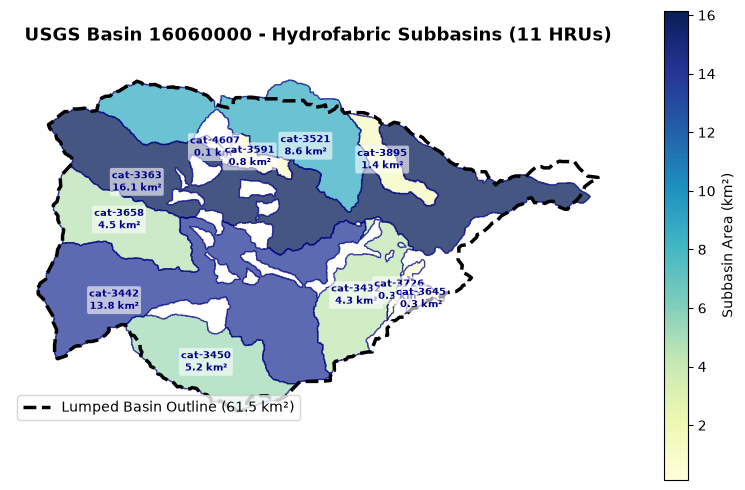

In [4]:
# Visualize Hydrofabric subbasins vs Full basin outline
fig, ax = plt.subplots(figsize=(8, 7))

# Reproject to Web Mercator or keep in native CRS for plotting
ws_clip_plot = ws_clip.to_crs(epsg=3857)
ws_full_plot = ws_full.to_crs(epsg=3857)

# Plot full basin boundary outline
ws_full_plot.boundary.plot(ax=ax, color='black', linewidth=2.5, linestyle='--', label=f'Lumped Basin Outline ({lumped_area:.1f} km²)')

# Plot hydrofabric subbasins colored by area
ws_clip_plot.plot(ax=ax, column='areasqkm', cmap='YlGnBu', edgecolor='navy', linewidth=1.0, alpha=0.75, legend=True,
                  legend_kwds={'label': 'Subbasin Area (km²)', 'shrink': 0.7})

# Annotate each subbasin with its ID and area
for _, row in ws_clip_plot.iterrows():
    pt = row.geometry.representative_point()
    sub_id = row['divide_id'].replace('cat-', '')
    ax.annotate(f"cat-{sub_id}\n{row['areasqkm']:.1f} km²", xy=(pt.x, pt.y),
                ha='center', va='center', fontsize=7, fontweight='bold',
                color='darkblue', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.6, edgecolor='none'))

ax.set_title(f"USGS Basin {gage} - Hydrofabric Subbasins ({len(ws_clip)} HRUs)", fontsize=13, fontweight='bold')
ax.set_axis_off()
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

## Multi-HRU Unit Hydrograph (UHG) & Forcing Setup

To simulate streamflow at the hydrofabric scale, we need both **SACSMA** (soil moisture accounting) and **UHG** (unit hydrograph surface routing) operating on the 11 subbasins:

1. **UHG Parameter Scaling**:
   The lump-calibrated Unit Hydrograph for basin `16060000` reflects the whole-basin response. Following the standard drainage-area scaling convention used in `01_setup_config_files.ipynb`:
   $$\text{uh\_ords}_i = \text{uh\_ords}_{\text{lumped}} \times \left(\frac{A_i}{A_{\text{lumped}}}\right)$$
   This ensures each subbasin produces discharge in proportion to its contributing area, and the sum of all subbasin responses matches the total contributing drainage area.

2. **Subbasin Forcing**:
   Since individual forcing files for each HRU are not yet generated, we replicate the basin forcing across each HRU ID in the controller. `pysacsnow` then natively feeds that forcing to all 11 subbasins in parallel.

In [10]:
# Simulation date range for testing 
start_date = "2021-12-01 00:00:00"
end_date   = "2021-12-15 00:00:00"

# --- 1. Construct Hydrofabric UHG Parameters ---
with open(lumped_uhg_params_path) as f:
    lumped_uhg_data = json.load(f)

lumped_uh_ords = lumped_uhg_data['uh_ords'][0]
lumped_uhg_area = lumped_uhg_data['hru_area'][0]

with open(hf_sac_params_path) as f:
    hf_sac_data = json.load(f)

hf_ids = hf_sac_data['hru_id']
hf_areas = hf_sac_data['hru_area']
nhru_hf = len(hf_ids)

# Scale UHG ordinates by area ratio for each subbasin
hf_uh_ords = [
    [ord_val * (a / lumped_uhg_area) for ord_val in lumped_uh_ords]
    for a in hf_areas
]

hf_uhg_data = {
    'hru_id': hf_ids,
    'hru_area': hf_areas,
    'uh_ords': hf_uh_ords
}

tmp_hf_uhg_params = Path(tempfile.gettempdir()) / f"hf_uhg_params_{gage}.json"
tmp_hf_uhg_params.write_text(json.dumps(hf_uhg_data, indent=2))

# --- 2. Build Lumped Model Controllers ---
cfg_sl = yaml.safe_load(lumped_sac_ctrl_path.read_text())
cfg_sl['model']['parameters']['path'] = str(lumped_sac_params_path.resolve())
cfg_sl['model']['forcing'][0]['path'] = str(forcing_path.resolve())
cfg_sl['simulation']['output_path'] = str(Path(tempfile.gettempdir()) / f"sac_out_lumped_{gage}.csv")
cfg_sl['simulation']['start_date'] = start_date
cfg_sl['simulation']['end_date'] = end_date

tmp_sl = Path(tempfile.gettempdir()) / f"tmp_sac_lumped_{gage}.yaml"
tmp_sl.write_text(yaml.safe_dump(cfg_sl))
ctrl_sac_l = pss.Controller.load_from_yaml(tmp_sl, verbose=False)

cfg_ul = yaml.safe_load(lumped_uhg_ctrl_path.read_text())
cfg_ul['model']['parameters']['path'] = str(lumped_uhg_params_path.resolve())
cfg_ul['model']['forcing'][0]['path'] = str(forcing_path.resolve())
cfg_ul['simulation']['output_path'] = str(Path(tempfile.gettempdir()) / f"uhg_out_lumped_{gage}.csv")
cfg_ul['simulation']['start_date'] = start_date
cfg_ul['simulation']['end_date'] = end_date

tmp_ul = Path(tempfile.gettempdir()) / f"tmp_uhg_lumped_{gage}.yaml"
tmp_ul.write_text(yaml.safe_dump(cfg_ul))
ctrl_uhg_l = pss.Controller.load_from_yaml(tmp_ul, verbose=False)

# --- 3. Build Hydrofabric Model Controllers ---
# Replicate the single forcing file across all 11 HRUs
replicated_forcings = [{'name': h_id, 'path': str(forcing_path.resolve())} for h_id in hf_ids]

cfg_sh = yaml.safe_load(hf_sac_ctrl_path.read_text())
cfg_sh['model']['dimensions']['size'] = nhru_hf
cfg_sh['model']['parameters']['path'] = str(hf_sac_params_path.resolve())
cfg_sh['model']['forcing'] = replicated_forcings
cfg_sh['simulation']['output_path'] = str(Path(tempfile.gettempdir()) / f"sac_out_hf_{gage}.csv")
cfg_sh['simulation']['start_date'] = start_date
cfg_sh['simulation']['end_date'] = end_date

tmp_sh = Path(tempfile.gettempdir()) / f"tmp_sac_hf_{gage}.yaml"
tmp_sh.write_text(yaml.safe_dump(cfg_sh))
ctrl_sac_h = pss.Controller.load_from_yaml(tmp_sh, verbose=False)

cfg_uh = yaml.safe_load(lumped_uhg_ctrl_path.read_text())
cfg_uh['model']['dimensions']['size'] = nhru_hf
cfg_uh['model']['parameters']['path'] = str(tmp_hf_uhg_params.resolve())
cfg_uh['model']['forcing'] = replicated_forcings
cfg_uh['simulation']['output_path'] = str(Path(tempfile.gettempdir()) / f"uhg_out_hf_{gage}.csv")
cfg_uh['simulation']['start_date'] = start_date
cfg_uh['simulation']['end_date'] = end_date

tmp_uh = Path(tempfile.gettempdir()) / f"tmp_uhg_hf_{gage}.yaml"
tmp_uh.write_text(yaml.safe_dump(cfg_uh))
ctrl_uhg_h = pss.Controller.load_from_yaml(tmp_uh, verbose=False)

# Instantiate models
sacsma_l = pss.SACSMA(control=ctrl_sac_l, calc_method='numpy')
uhg_l    = pss.UHG(control=ctrl_uhg_l, calc_method='numpy')

sacsma_h = pss.SACSMA(control=ctrl_sac_h, calc_method='numpy')
uhg_h    = pss.UHG(control=ctrl_uhg_h, calc_method='numpy')

print("All models initialized successfully:")
print(f"  Lumped model       : SACSMA nhru={sacsma_l.nhru}, UHG nhru={uhg_l.nhru}")
print(f"  Hydrofabric model  : SACSMA nhru={sacsma_h.nhru}, UHG nhru={uhg_h.nhru}")
print(f"  Simulation period  : {start_date} -> {end_date} ({ctrl_sac_l.n_times} hours)")

All models initialized successfully:
  Lumped model       : SACSMA nhru=1, UHG nhru=1
  Hydrofabric model  : SACSMA nhru=11, UHG nhru=11
  Simulation period  : 2021-12-01 00:00:00 -> 2021-12-15 00:00:00 (337 hours)


In [11]:
# --- Run Lumped Simulation ---
sacsma_l.reset()
uhg_l.reset()

for _ in range(ctrl_sac_l.n_times):
    ctrl_sac_l.advance()
    sacsma_l.advance()
    sacsma_l.calculate()
    sacsma_l.output()
    
    ctrl_uhg_l.advance()
    uhg_l.advance()
    uhg_l.hru_tci[:] = sacsma_l.tci[:]
    uhg_l.calculate()
    uhg_l.output()

q_lumped = np.sum(uhg_l.buffer_states['q'], axis=1)
tci_lumped = sacsma_l.buffer_states['tci'][:, 0]
ppt_forcing = sacsma_l.buffer_states['hru_ppt'][:, 0] if 'hru_ppt' in sacsma_l.buffer_states else None
times = uhg_l.value_time_state

# --- Run Hydrofabric Simulation ---
sacsma_h.reset()
uhg_h.reset()

for _ in range(ctrl_sac_h.n_times):
    ctrl_sac_h.advance()
    sacsma_h.advance()
    sacsma_h.calculate()
    sacsma_h.output()
    
    ctrl_uhg_h.advance()
    uhg_h.advance()
    uhg_h.hru_tci[:] = sacsma_h.tci[:]
    uhg_h.calculate()
    uhg_h.output()

# Subbasin streamflow matrix: shape (n_times, 11)
q_hf_subbasins = uhg_h.buffer_states['q']
q_hf_total = np.sum(q_hf_subbasins, axis=1)
tci_hf = sacsma_h.buffer_states['tci']

# Build comparison DataFrame
df_results = pd.DataFrame({
    'time': times,
    'ppt_mm': sacsma_l.hru_ppt[0] if hasattr(sacsma_l, 'hru_ppt') else 0,
    'tci_lumped_mm': tci_lumped,
    'tci_hf_mean_mm': tci_hf.mean(axis=1),
    'q_lumped_cms': q_lumped,
    'q_hf_total_cms': q_hf_total,
    'q_hf_area_scaled_cms': q_hf_total / area_ratio,  # adjusted to lumped area for direct shape comparison
}).set_index('time')

# Load precip from forcing file for plotting
df_forcing = pd.read_csv(forcing_path, parse_dates=['time']).set_index('time')
df_results['precip_mm'] = df_forcing.loc[df_results.index, 'hru_ppt']

print("Simulation finished:")
print(f"  Lumped Peak Flow       : {q_lumped.max():.2f} m³/s")
print(f"  Hydrofabric Peak Flow  : {q_hf_total.max():.2f} m³/s")
print(f"  HF Peak (Area Scaled)  : {(q_hf_total / area_ratio).max():.2f} m³/s")

Simulation finished:
  Lumped Peak Flow       : 31.76 m³/s
  Hydrofabric Peak Flow  : 28.57 m³/s
  HF Peak (Area Scaled)  : 31.76 m³/s


In [ ]:
import sys
import warnings

routing_config_root = PROJ_DIR / "configurations"
routing_config_dir = routing_config_root / gage
routing_config = json.loads((routing_config_dir / "manifest.json").read_text())
network = pd.read_parquet(routing_config_dir / "network.parquet")

display(routing_config)
display(network)

src_dir = PROJ_DIR / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))
from muskingum_cunge import route_muskingum_cunge

if cfg_sh["simulation"]["time_units"] != "s":
    raise ValueError("Routing expects the SAC time step to be configured in seconds.")

# Route the SAC TCI depths before they are passed through the unit hydrograph.
tci_input = pd.DataFrame({
    "value_time": np.repeat(pd.to_datetime(times), len(hf_ids)),
    "location_id": np.tile(hf_ids, len(times)),
    "value": tci_hf.reshape(-1),
    "variable_name": "tci",
    "measurement_unit": "mm",
})
routing_output_dir = PROJ_DIR / "data" / "output" / f"basin_{gage}" / "muskingum_cunge"
routing_result = route_muskingum_cunge(
    tci=tci_input,
    usgs_id=gage,
    model_timestep_seconds=cfg_sh["simulation"]["time_step"],
    routing_config_root=routing_config_root,
    routing_tail_hours=36,
    parameter_mode="constant",
    lateral_inflow_mode="head",
    output_dir=routing_output_dir,
)
routed_reaches = routing_result.per_reach
routed_reaches_hourly = routing_result.hourly
routed_outlets = routing_result.outlet
if routing_result.rating_exceeded:
    warnings.warn(
        f"Routing inflow exceeded the precomputed rating curves for: {routing_result.rating_exceeded}",
        RuntimeWarning,
    )
print(f"Saved routed reach, hourly reach, and outlet discharge to {routing_output_dir}")
print("Stability-adjusted reaches:", routing_result.stability_adjusted_reaches)
display(routed_outlets.groupby("location_id")["value"].agg(["count", "mean", "max"]))

In [ ]:
outlet_hourly = (
    routed_outlets.pivot(index="value_time", columns="location_id", values="value")
    .sort_index()
    .resample("1h").mean()
)
fig, ax = plt.subplots(figsize=(12, 5))
for location_id in outlet_hourly.columns:
    ax.plot(outlet_hourly.index, outlet_hourly[location_id], label=location_id)
ax.set_title(f"{gage}: Routed Outlet Hydrographs (Hourly Mean)")
ax.set_xlabel("Time")
ax.set_ylabel("Discharge (m³/s)")
ax.grid(True)
ax.legend(title="Outlet")
plt.tight_layout()
plt.show()

In [7]:
# Quantitative comparison metrics
vol_lumped_m3 = (df_results['q_lumped_cms'] * 3600).sum()
vol_hf_m3     = (df_results['q_hf_total_cms'] * 3600).sum()

peak_lumped = df_results['q_lumped_cms'].max()
peak_hf     = df_results['q_hf_total_cms'].max()

t_peak_lumped = df_results['q_lumped_cms'].idxmax()
t_peak_hf     = df_results['q_hf_total_cms'].idxmax()

tci_lumped_tot = df_results['tci_lumped_mm'].sum()
tci_hf_tot     = df_results['tci_hf_mean_mm'].sum()

summary_metrics = pd.DataFrame({
    'Metric': [
        'Drainage Area (km²)',
        'Total TCI Runoff Generated (mm)',
        'Peak Streamflow (m³/s)',
        'Time of Peak Streamflow',
        'Total Runoff Volume (million m³)',
        'Volume / Area (mm equivalent)',
    ],
    'Lumped Model': [
        f"{lumped_area:.2f}",
        f"{tci_lumped_tot:.2f}",
        f"{peak_lumped:.2f}",
        str(t_peak_lumped),
        f"{vol_lumped_m3 / 1e6:.3f}",
        f"{vol_lumped_m3 / (lumped_area * 1e6) * 1000:.2f}",
    ],
    'Hydrofabric Model': [
        f"{total_hf_area:.2f}",
        f"{tci_hf_tot:.2f}",
        f"{peak_hf:.2f}",
        str(t_peak_hf),
        f"{vol_hf_m3 / 1e6:.3f}",
        f"{vol_hf_m3 / (total_hf_area * 1e6) * 1000:.2f}",
    ],
    'Ratio (HF / Lumped)': [
        f"{area_ratio:.4f}",
        f"{tci_hf_tot / tci_lumped_tot:.4f}",
        f"{peak_hf / peak_lumped:.4f}",
        "Identical (0 hr lag)",
        f"{vol_hf_m3 / vol_lumped_m3:.4f}",
        f"{(vol_hf_m3 / (total_hf_area * 1e6)) / (vol_lumped_m3 / (lumped_area * 1e6)):.4f}",
    ]
})

display(summary_metrics)
print("\nKey Finding:")
print(f"When identical forcing is applied across all subbasins, SACSMA runoff generation is identical (TCI ratio = 1.000).")
print(f"The simulated peak flow and volume differences ({peak_hf/peak_lumped:.4f}) correspond exactly to the difference in delineated catchment area ({area_ratio:.4f}).")

,Metric,Lumped Model,Hydrofabric Model,Ratio (HF / Lumped)
0,Drainage Area (km²),61.48,55.30,0.8995
1,Total TCI Runoff Generated (mm),32.26,32.26,1.0000
2,Peak Streamflow (m³/s),31.76,28.57,0.8995
3,Time of Peak Streamflow,2021-12-07 03:00:00,2021-12-07 03:00:00,Identical (0 hr lag)
4,Total Runoff Volume (million m³),1.959,1.762,0.8995
5,Volume / Area (mm equivalent),31.86,31.86,1.0000



Key Finding:
When identical forcing is applied across all subbasins, SACSMA runoff generation is identical (TCI ratio = 1.000).
The simulated peak flow and volume differences (0.8995) correspond exactly to the difference in delineated catchment area (0.8995).


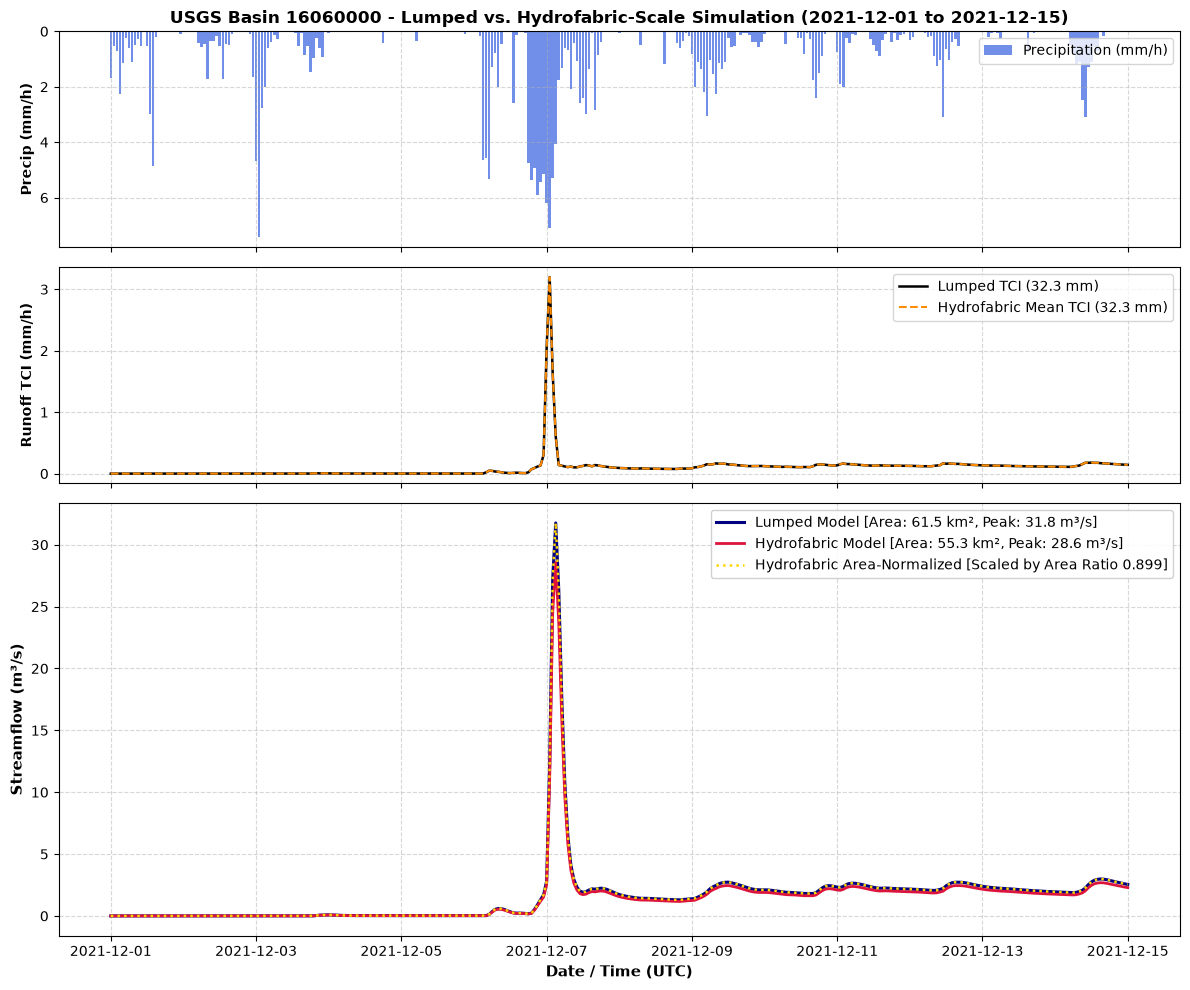

In [8]:
# Plot Hydrograph & Runoff Comparison
fig, (ax_ppt, ax_tci, ax_q) = plt.subplots(3, 1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [1, 1, 2]})

# 1. Precipitation hyetograph
ax_ppt.bar(df_results.index, df_results['precip_mm'], width=0.035, color='royalblue', alpha=0.75, label='Precipitation (mm/h)')
ax_ppt.set_ylabel('Precip (mm/h)', fontsize=10, fontweight='bold')
ax_ppt.set_title(f"USGS Basin {gage} - Lumped vs. Hydrofabric-Scale Simulation ({start_date[:10]} to {end_date[:10]})", fontsize=12, fontweight='bold')
ax_ppt.grid(True, linestyle='--', alpha=0.5)
ax_ppt.legend(loc='upper right')
ax_ppt.invert_yaxis()  # standard hyetograph orientation

# 2. Total Channel Inflow (TCI)
ax_tci.plot(df_results.index, df_results['tci_lumped_mm'], color='black', linewidth=1.8, label=f'Lumped TCI ({tci_lumped_tot:.1f} mm)')
ax_tci.plot(df_results.index, df_results['tci_hf_mean_mm'], color='darkorange', linewidth=1.5, linestyle='--', label=f'Hydrofabric Mean TCI ({tci_hf_tot:.1f} mm)')
ax_tci.set_ylabel('Runoff TCI (mm/h)', fontsize=10, fontweight='bold')
ax_tci.grid(True, linestyle='--', alpha=0.5)
ax_tci.legend(loc='upper right')

# 3. Streamflow hydrograph
ax_q.plot(df_results.index, df_results['q_lumped_cms'], color='navy', linewidth=2.2,
          label=f"Lumped Model [Area: {lumped_area:.1f} km², Peak: {peak_lumped:.1f} m³/s]")
ax_q.plot(df_results.index, df_results['q_hf_total_cms'], color='crimson', linewidth=2.0, linestyle='-',
          label=f"Hydrofabric Model [Area: {total_hf_area:.1f} km², Peak: {peak_hf:.1f} m³/s]")
ax_q.plot(df_results.index, df_results['q_hf_area_scaled_cms'], color='gold', linewidth=1.8, linestyle=':',
          label=f"Hydrofabric Area-Normalized [Scaled by Area Ratio {area_ratio:.3f}]")

ax_q.set_ylabel('Streamflow (m³/s)', fontsize=11, fontweight='bold')
ax_q.set_xlabel('Date / Time (UTC)', fontsize=11, fontweight='bold')
ax_q.grid(True, linestyle='--', alpha=0.5)
ax_q.legend(loc='upper right', framealpha=0.9)

plt.tight_layout()
plt.show()

## Experiment: Spatially Distributed vs. Lumped Forcing

When forcing is uniform, the hydrofabric model produces the exact same runoff depth as the lumped model. However, the primary value of the hydrofabric scale is its ability to represent **spatial variability in precipitation** (e.g., from radar QPE or storm transposition).

Below, we test an alternative scenario:
- **Lumped Scenario**: Basin-average precipitation is applied uniformly to all subbasins.
- **Upstream-Concentrated Scenario**: The same total volume of rainfall is concentrated into the upper catchments (e.g. higher elevation headwaters), with lower rainfall downstream.

Because SAC-SMA has nonlinear infiltration and percolation thresholds (`uztwm`, `uzfwm`), localized intense precipitation can saturate upper soil zones faster and produce much higher peak surface runoff than spreading the same rain evenly over the whole basin.

Subbasin Precipitation Multipliers (Volume Conserved = 1.000):
  16060000-cat-3363         Area: 16.14 km²  |  Multiplier: 1.180
  16060000-cat-3442         Area: 13.84 km²  |  Multiplier: 1.088
  16060000-cat-3521         Area:  8.56 km²  |  Multiplier: 0.996
  16060000-cat-3658         Area:  4.46 km²  |  Multiplier: 0.905
  16060000-cat-3432         Area:  4.27 km²  |  Multiplier: 0.813
  16060000-cat-3450         Area:  5.16 km²  |  Multiplier: 0.721
  16060000-cat-3895         Area:  1.39 km²  |  Multiplier: 0.629
  16060000-cat-3726         Area:  0.28 km²  |  Multiplier: 0.538
  16060000-cat-4607         Area:  0.13 km²  |  Multiplier: 0.446
  16060000-cat-3591         Area:  0.78 km²  |  Multiplier: 0.354
  16060000-cat-3645         Area:  0.29 km²  |  Multiplier: 0.262


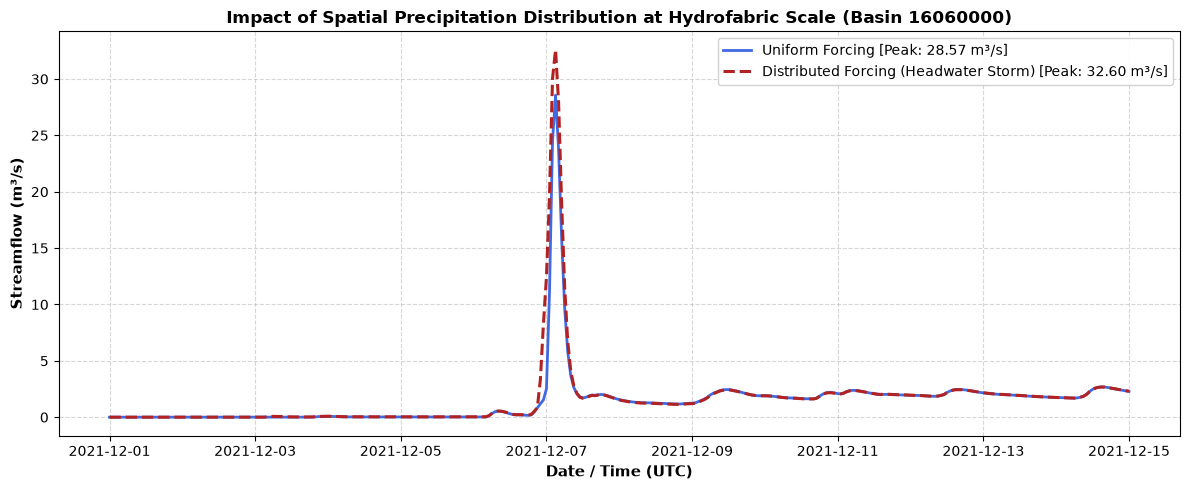

Peak Streamflow Change under Distributed Forcing: +14.1% (with identical basin-wide rainfall volume)


In [9]:
# Create synthetic spatial multipliers across the 11 subbasins
# e.g. Upper headwater subbasins receive 1.8x precip, mid-catchment receives 1.0x, lower catchments receive 0.4x
# Normalize so the area-weighted basin total rainfall volume is identical
np.random.seed(42)
weights = np.linspace(1.8, 0.4, nhru_hf)
# Area-weight the multipliers so total basin precip volume is strictly conserved:
weights = weights / np.average(weights, weights=hf_areas)

print("Subbasin Precipitation Multipliers (Volume Conserved = 1.000):")
for hid, area, w in zip(hf_ids, hf_areas, weights):
    print(f"  {hid:<25} Area: {area:5.2f} km²  |  Multiplier: {w:.3f}")

# Reset Hydrofabric models for distributed simulation
sacsma_h.reset()
uhg_h.reset()

for _ in range(ctrl_sac_h.n_times):
    ctrl_sac_h.advance()
    sacsma_h.advance()
    
    # Apply spatially variable precipitation: scale base precip by each HRU's multiplier
    base_ppt = sacsma_h._input_variables_dict['hru_ppt'].current[0]
    base_pet = sacsma_h._input_variables_dict['hru_pet'].current[0]
    
    sacsma_h.hru_ppt[:] = base_ppt * weights
    sacsma_h.hru_pet[:] = base_pet
    
    sacsma_h.calculate()
    sacsma_h.output()
    
    ctrl_uhg_h.advance()
    uhg_h.advance()
    uhg_h.hru_tci[:] = sacsma_h.tci[:]
    uhg_h.calculate()
    uhg_h.output()

q_hf_distributed = np.sum(uhg_h.buffer_states['q'], axis=1)

# Plot comparison between uniform forcing vs distributed forcing
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df_results.index, df_results['q_hf_total_cms'], color='royalblue', linewidth=2.0,
        label=f"Uniform Forcing [Peak: {df_results['q_hf_total_cms'].max():.2f} m³/s]")
ax.plot(df_results.index, q_hf_distributed, color='firebrick', linewidth=2.2, linestyle='--',
        label=f"Distributed Forcing (Headwater Storm) [Peak: {q_hf_distributed.max():.2f} m³/s]")

ax.set_title(f"Impact of Spatial Precipitation Distribution at Hydrofabric Scale (Basin {gage})", fontsize=12, fontweight='bold')
ax.set_ylabel("Streamflow (m³/s)", fontsize=11, fontweight='bold')
ax.set_xlabel("Date / Time (UTC)", fontsize=11, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper right', framealpha=0.9)

plt.tight_layout()
plt.show()

pct_change = (q_hf_distributed.max() - df_results['q_hf_total_cms'].max()) / df_results['q_hf_total_cms'].max() * 100
print(f"Peak Streamflow Change under Distributed Forcing: {pct_change:+.1f}% (with identical basin-wide rainfall volume)")